In [15]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 전처리한 데이터 불러오기
sales = pd.read_csv("output/sales_clean.csv")

# 날짜를 날짜형으로 변환
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])

# 데이터 확인
print("데이터 크기:", sales.shape)
sales.head()


C:\Users\leejy\AppData\Local\Temp\ipykernel_20932\1223202320.py:6: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv("output/sales_clean.csv")


데이터 크기: (524878, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [16]:

# 월별 매출 계산
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")

monthly_sales = sales.groupby("YearMonth")["Sales"].sum()

# 결과 확인
monthly_sales


YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Sales, dtype: float64

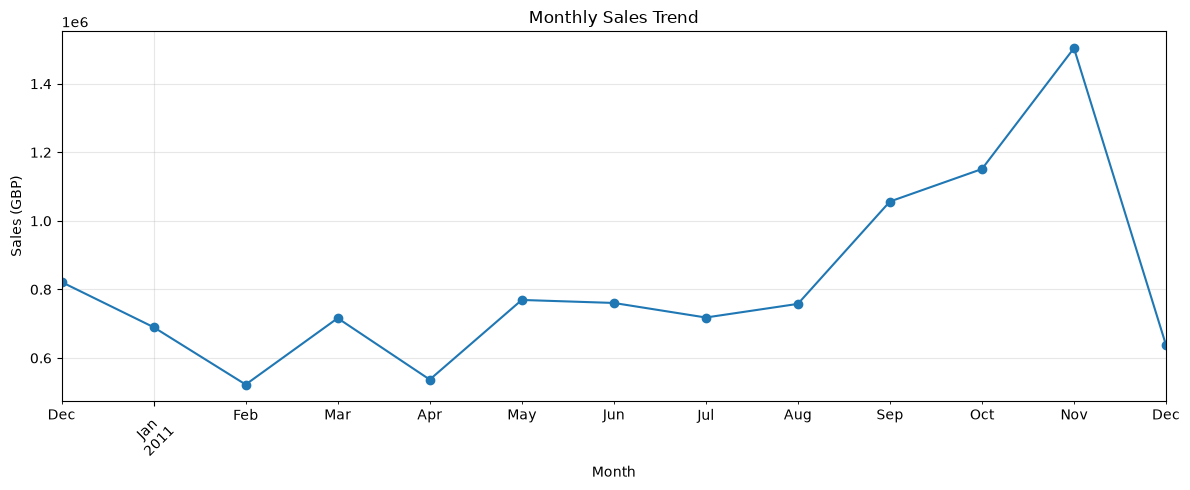

In [17]:

plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (GBP)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

# 월별 매출과 전월 대비 증감률 계산
monthly_df = monthly_sales.to_frame(name="Sales")

monthly_df["Growth_Rate"] = (
    monthly_df["Sales"].pct_change() * 100
)

# 소수점 둘째 자리까지 표시
monthly_df.round(2)


,Sales,Growth_Rate
YearMonth,,
2010-12,821452.73,NaN
2011-01,689811.61,-16.03
2011-02,522545.56,-24.25
2011-03,716215.26,37.06
2011-04,536968.49,-25.03
2011-05,769296.61,43.27
2011-06,760547.01,-1.14
2011-07,718076.12,-5.58
2011-08,757841.38,5.54


In [19]:

# 전체 월이 포함된 2011년 1~11월만 비교
monthly_full = monthly_df.loc[
    "2011-01":"2011-11"
]

print("매출 최고 월:")
print(monthly_full["Sales"].idxmax())

print("최고 월 매출:")
print(round(monthly_full["Sales"].max(), 2))

print("매출 최저 월:")
print(monthly_full["Sales"].idxmin())


매출 최고 월:
2011-11
최고 월 매출:
1503866.78
매출 최저 월:
2011-02


In [20]:

# 월별 주문 수 계산
monthly_orders = sales.groupby("YearMonth")["InvoiceNo"].nunique()

monthly_orders


YearMonth
2010-12    1559
2011-01    1086
2011-02    1100
2011-03    1454
2011-04    1246
2011-05    1681
2011-06    1533
2011-07    1476
2011-08    1361
2011-09    1838
2011-10    2040
2011-11    2769
2011-12     819
Freq: M, Name: InvoiceNo, dtype: int64

In [21]:

# 월별 매출, 주문 수, 객단가 계산
monthly_analysis = pd.DataFrame({
    "Sales": monthly_sales,
    "Orders": monthly_orders
})

monthly_analysis["AOV"] = (
    monthly_analysis["Sales"] / monthly_analysis["Orders"]
)

monthly_analysis.round(2)


,Sales,Orders,AOV
YearMonth,,,
2010-12,821452.73,1559,526.91
2011-01,689811.61,1086,635.19
2011-02,522545.56,1100,475.04
2011-03,716215.26,1454,492.58
2011-04,536968.49,1246,430.95
2011-05,769296.61,1681,457.64
2011-06,760547.01,1533,496.12
2011-07,718076.12,1476,486.50
2011-08,757841.38,1361,556.83


In [22]:

# 전월 대비 증감률 계산
monthly_analysis["Sales_Growth"] = (
    monthly_analysis["Sales"].pct_change() * 100
)

monthly_analysis["Orders_Growth"] = (
    monthly_analysis["Orders"].pct_change() * 100
)

monthly_analysis["AOV_Growth"] = (
    monthly_analysis["AOV"].pct_change() * 100
)

# 2011년 9~11월 결과 확인
monthly_analysis.loc["2011-09":"2011-11"].round(2)


,Sales,Orders,AOV,Sales_Growth,Orders_Growth,AOV_Growth
YearMonth,,,,,,
2011-09,1056435.19,1838,574.77,39.40,35.05,3.22
2011-10,1151263.73,2040,564.34,8.98,10.99,-1.81
2011-11,1503866.78,2769,543.11,30.63,35.74,-3.76


In [23]:

# 상품별 매출 합계 계산
product_sales = (
    sales.groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

# 매출 상위 10개 상품
product_sales.head(10)


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Sales, dtype: float64

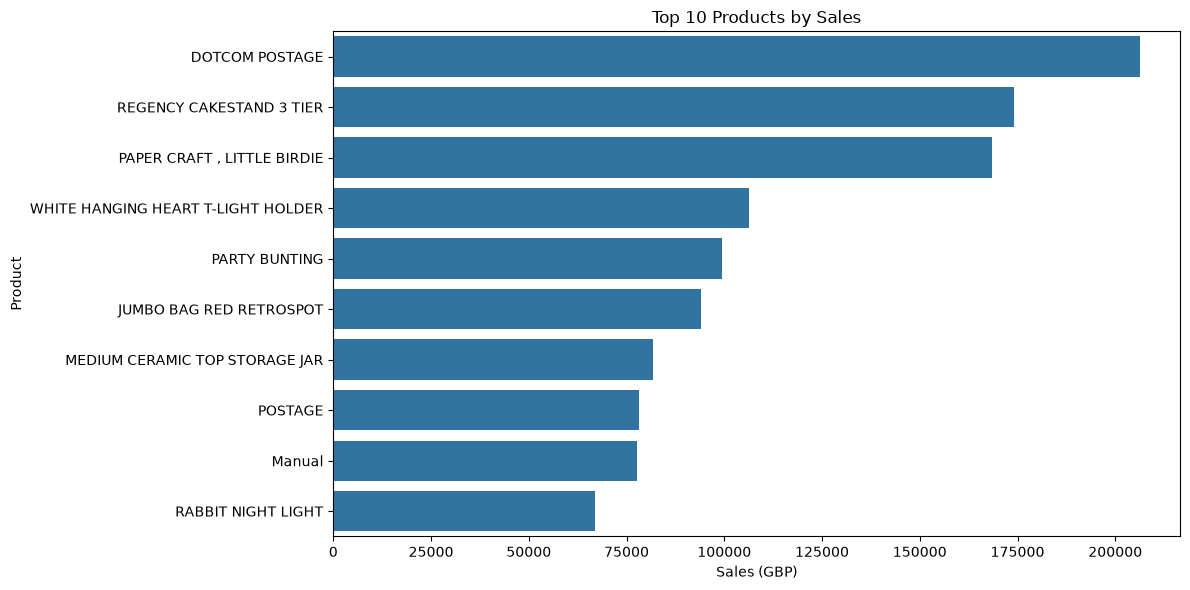

In [24]:

# 상위 10개 상품 선택
top10 = product_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top10.values,
    y=top10.index
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales (GBP)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [25]:

# 일반 상품이 아닌 항목 확인
exclude_items = [
    "DOTCOM POSTAGE",
    "POSTAGE",
    "Manual"
]

# 해당 항목을 제외한 데이터
product_data = sales[
    ~sales["Description"].isin(exclude_items)
].copy()

# 상품별 매출 다시 계산
product_sales_clean = (
    product_data.groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

product_sales_clean.head(10)


Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Sales, dtype: float64

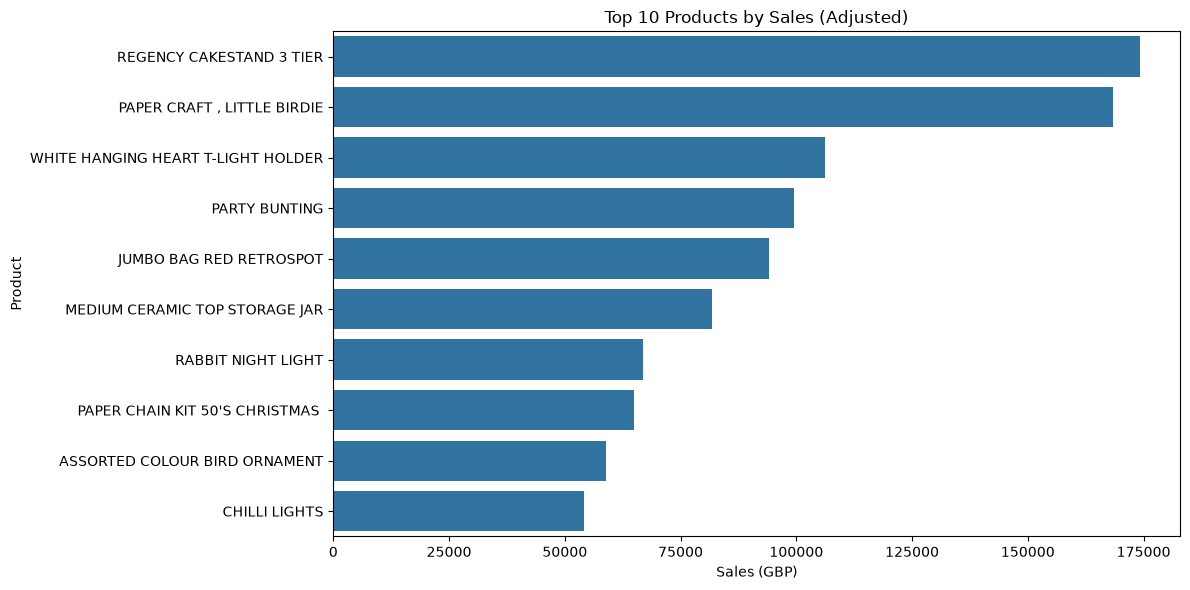

In [26]:

top10_clean = product_sales_clean.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top10_clean.values,
    y=top10_clean.index
)

plt.title("Top 10 Products by Sales (Adjusted)")
plt.xlabel("Sales (GBP)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [27]:

# 상위 10개 상품 매출 비중
top10_sales = product_sales_clean.head(10).sum()

total_product_sales = product_sales_clean.sum()

top10_ratio = top10_sales / total_product_sales * 100

print("상위 10개 상품 매출 비중:", round(top10_ratio, 2), "%")


상위 10개 상품 매출 비중: 9.43 %


In [30]:


# 비상품성 항목 확인
exclude_keywords = [
    "POSTAGE",
    "CARRIAGE",
    "MANUAL",
    "DISCOUNT",
    "BANK CHARGES",
    "AMAZON FEE"
]

non_product = product_data[
    product_data["Description"].fillna("")
    .str.upper()
    .str.contains("|".join(exclude_keywords), regex=True)
]

print("비상품성 의심 거래 수:", len(non_product))

non_product[
    ["StockCode", "Description", "Quantity", "UnitPrice"]
].head(20)


비상품성 의심 거래 수: 328


,StockCode,Description,Quantity,UnitPrice
1376,C2,CARRIAGE,1,50.00
4296,BANK CHARGES,Bank Charges,1,15.00
11720,C2,CARRIAGE,1,50.00
12041,C2,CARRIAGE,1,50.00
14456,AMAZONFEE,AMAZON FEE,1,13541.33
19267,C2,CARRIAGE,1,50.00
19304,C2,CARRIAGE,1,50.00
33127,C2,CARRIAGE,1,50.00
33477,C2,CARRIAGE,1,50.00
36379,C2,CARRIAGE,1,50.00


In [31]:

# 비상품성 의심 항목별 거래 수 확인
non_product_summary = (
    non_product.groupby(
        ["StockCode", "Description"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

# 결과 확인
print("비상품성 의심 항목 종류:",
      len(non_product_summary))

non_product_summary.head(30)


비상품성 의심 항목 종류: 6


,StockCode,Description,Count
5,C2,CARRIAGE,141
1,23444,Next Day Carriage,79
0,23099,FRENCH CARRIAGE LANTERN,59
2,85168B,BLACK BAROQUE CARRIAGE CLOCK,35
4,BANK CHARGES,Bank Charges,12
3,AMAZONFEE,AMAZON FEE,2


In [32]:

# 제외할 상품 코드
exclude_codes = [
    "C2",
    "23444",
    "BANK CHARGES",
    "AMAZONFEE"
]

# 비상품성 항목을 제외한 데이터 생성
product_final = product_data[
    ~product_data["StockCode"].astype(str).isin(exclude_codes)
].copy()

print("기존 데이터:", len(product_data))
print("정제 후 데이터:", len(product_final))
print("제외된 거래:", len(product_data) - len(product_final))


기존 데이터: 522729
정제 후 데이터: 522495
제외된 거래: 234


In [33]:

# 매출 계산
product_final["Sales"] = (
    product_final["Quantity"] *
    product_final["UnitPrice"]
)

# 상품별 매출 집계
product_top10 = (
    product_final.groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

product_top10.round(2)


Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Sales, dtype: float64

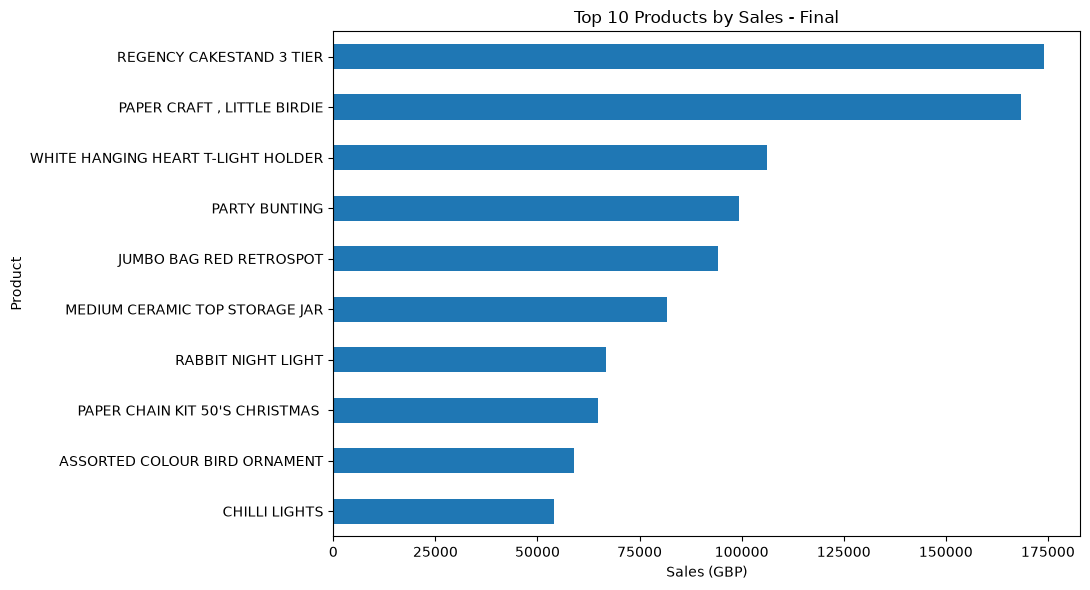

In [34]:

plt.figure(figsize=(11, 6))

product_top10.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Sales - Final")
plt.xlabel("Sales (GBP)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


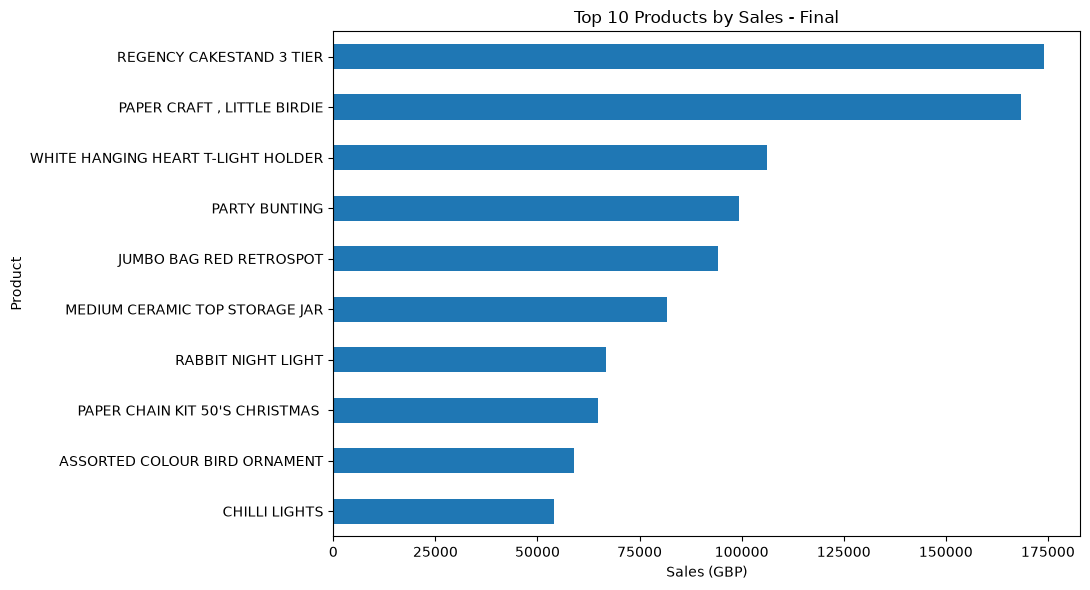

상품 매출 그래프 저장 완료


In [35]:

from pathlib import Path

# output 폴더 생성
Path("output").mkdir(exist_ok=True)

# 최종 상품 매출 TOP 10 그래프
plt.figure(figsize=(11, 6))

product_top10.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Sales - Final")
plt.xlabel("Sales (GBP)")
plt.ylabel("Product")
plt.tight_layout()

# 그래프 저장
plt.savefig(
    "output/product_top10_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("상품 매출 그래프 저장 완료")


In [36]:

product_top10.to_csv(
    "output/product_top10_final.csv",
    encoding="utf-8-sig",
    header=["Sales_GBP"]
)

print("상품 매출 분석표 저장 완료")


상품 매출 분석표 저장 완료


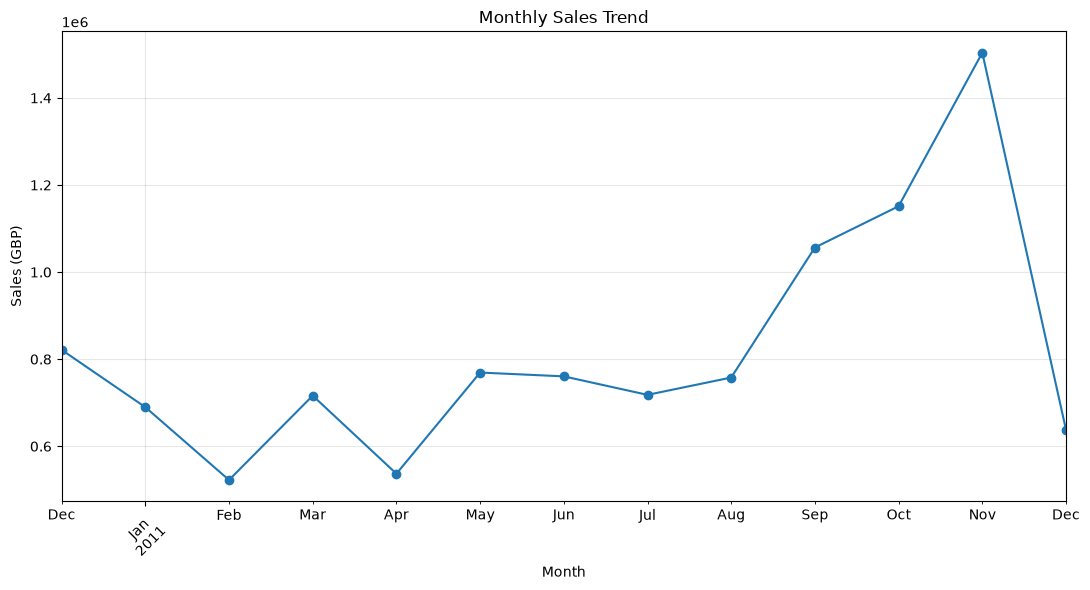

월별 매출 그래프 저장 완료


In [37]:

# 월별 매출 추이 그래프
plt.figure(figsize=(11, 6))

monthly_df["Sales"].plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (GBP)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

# 그래프 저장
plt.savefig(
    "output/monthly_sales_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("월별 매출 그래프 저장 완료")


In [38]:

# 월별 매출 및 성장률 분석표 저장
monthly_analysis.to_csv(
    "output/monthly_sales_final.csv",
    encoding="utf-8-sig"
)

print("월별 매출 분석표 저장 완료")


월별 매출 분석표 저장 완료
